# Lab 2 · Exercise A — Anatomy of a fit
Same data and model as Lab 1, Exercise C. This time we call **MIGRAD, HESSE and MINOS** ourselves with `RooMinimizer`.

In [1]:
import ROOT
# static PNG plots (visible on GitHub); %jsroot on for interactive plots
%jsroot off
import numpy as np

MATRICOLA = 1263603
assert MATRICOLA != 0, "Set MATRICOLA first: it seeds YOUR random toy data"

ROOT.RooRandom.randomGenerator().SetSeed(MATRICOLA)
ROOT.RooMsgService.instance().setGlobalKillBelow(ROOT.RooFit.WARNING)

def check(name, ok):
    """Minimal self-check: prints PASS/FAIL and stops the notebook on FAIL."""
    print(("PASS  " if ok else "FAIL  ") + name)
    assert ok, name

In [2]:
# range extended to 5560 as in Lab 1 C: the event at 5540.88 MeV is dropped by read() otherwise
m = ROOT.RooRealVar("m", "mass", 5080, 5560, "MeV/c^2")
data = ROOT.RooDataSet.read("../../examples/lhcb-b0-ppbar/data/rarest_b0_decay.dat", ROOT.RooArgSet(m), "D")

mean  = ROOT.RooRealVar("mean", "mean", 5280, 5200, 5350)
sigma = ROOT.RooRealVar("sigma", "sigma", 15, 5, 50)
slope = ROOT.RooRealVar("slope", "slope", -0.002, -0.02, 0)
sig   = ROOT.RooGaussian("sig", "sig", m, mean, sigma)
bkg   = ROOT.RooExponential("bkg", "bkg", m, slope)
nsig  = ROOT.RooRealVar("nsig", "signal yield", 30, 0, 166)
nbkg  = ROOT.RooRealVar("nbkg", "background yield", 130, 0, 500)
model = ROOT.RooAddPdf("model", "sig+bkg", ROOT.RooArgList(sig, bkg), ROOT.RooArgList(nsig, nbkg))
params = ROOT.RooArgSet(mean, sigma, slope, nsig, nbkg)
print(data.numEntries(), "events")

166 events


#### Visualize the Data

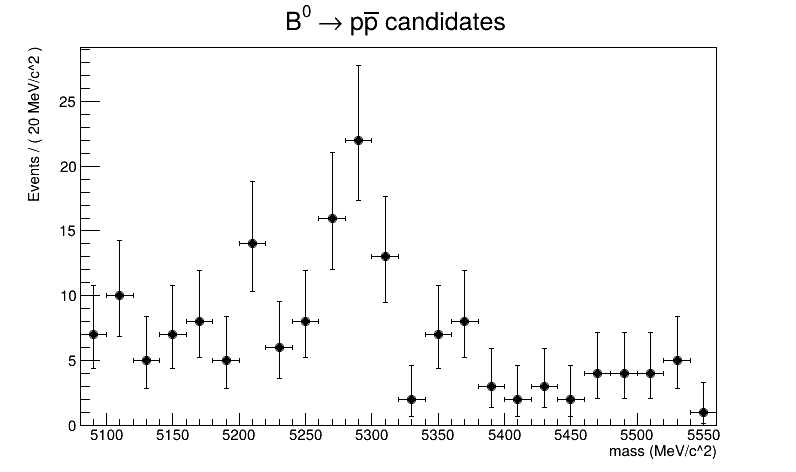

In [3]:
frame0 = m.frame(ROOT.RooFit.Title("B^{0} #rightarrow p#bar{p} candidates"), ROOT.RooFit.Bins(24))   # 20 MeV bins
data.plotOn(frame0)
c0 = ROOT.TCanvas("c0", "c0", 800, 500)
frame0.Draw()
c0.Draw()

## A1 · NLL, MIGRAD, HESSE

`fitTo()` is just a wrapper. Let's do it explicitly:
1. Create the extended NLL, 
2. initialize a minimizer
3. run Minuit2 MIGRAD, 
4. then HESSE. 

Save the result and read the status, the EDM and `covQual`.

In [4]:
# 1. Build NLL
nll   = model.createNLL(data, ROOT.RooFit.Extended(True))
# 2. Initialize Minimizer
minim = ROOT.RooMinimizer(nll)

# 3. Run MIGRAD
minim.setPrintLevel(-1)
minim.minimize("Minuit2", "Migrad")
# 4. Run HESSE
minim.hesse()
res = minim.save()

err_hesse = nsig.getError()      # keep it: MINOS will update the error object later
print("status =", res.status(), " covQual =", res.covQual(), " EDM =", res.edm())
print("nsig = %.2f +- %.2f (HESSE)" % (nsig.getVal(), err_hesse))
res.Print()

# Notice how nsig and nbkg have updated automatically!

status = 0  covQual = 3  EDM = 4.974590712171188e-05
nsig = 33.99 +- 7.91 (HESSE)

  RooFitResult: minimized FCN value: 315.283, estimated distance to minimum: 4.97459e-05
                covariance matrix quality: Full, accurate covariance matrix
                Status : MINIMIZE=0 HESSE=0 

    Floating Parameter    FinalValue +/-  Error   
  --------------------  --------------------------
                  mean    5.2879e+03 +/-  4.00e+00
                  nbkg    1.3203e+02 +/-  1.27e+01
                  nsig    3.3989e+01 +/-  7.91e+00
                 sigma    1.5017e+01 +/-  3.47e+00
                 slope   -2.3995e-03 +/-  6.50e-04



In [5]:
check("minimiser objects exist", nll is not None and minim is not None and res is not None)
check("fit converged (status 0)", res.status() == 0)
check("full covariance matrix (covQual 3)", res.covQual() == 3)

PASS  minimiser objects exist
PASS  fit converged (status 0)
PASS  full covariance matrix (covQual 3)


#### Visualize data and model

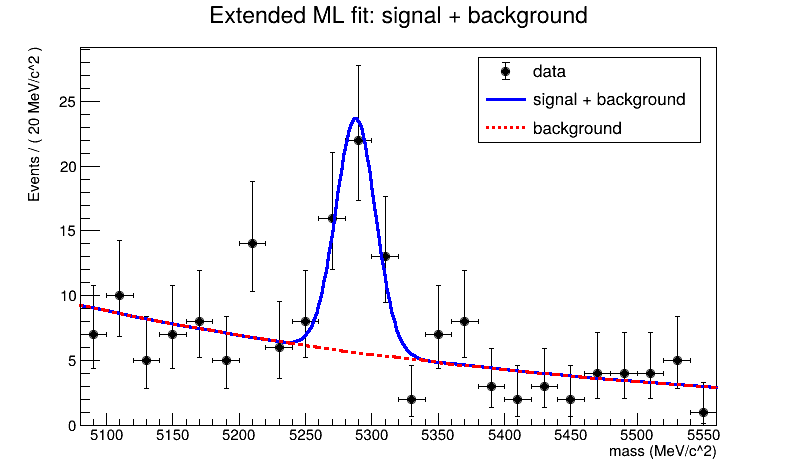

In [6]:
frame1 = m.frame(ROOT.RooFit.Title("Extended ML fit: signal + background"), ROOT.RooFit.Bins(24))
data.plotOn(frame1, ROOT.RooFit.Name("data"))
model.plotOn(frame1, ROOT.RooFit.Name("model"))
model.plotOn(frame1, ROOT.RooFit.Components("bkg"), ROOT.RooFit.LineStyle(ROOT.kDashed),
             ROOT.RooFit.LineColor(ROOT.kRed), ROOT.RooFit.Name("bkg"))

leg1 = ROOT.TLegend(0.60, 0.70, 0.88, 0.88)
leg1.AddEntry(frame1.findObject("data"), "data", "pe")
leg1.AddEntry(frame1.findObject("model"), "signal + background", "l")
leg1.AddEntry(frame1.findObject("bkg"), "background", "l")

c1 = ROOT.TCanvas("c1", "c1", 800, 500)
frame1.Draw()
leg1.Draw()
c1.Draw()

## A2 · MINOS
Compute MINOS errors for `nsig` only. Compare with HESSE.

In [7]:
# Run MINOS on nsig
minim.minos(ROOT.RooArgSet(nsig))
lo = nsig.getErrorLo()
hi = nsig.getErrorHi()
print("MINOS: nsig = %.2f  %+.2f / %+.2f" % (nsig.getVal(), lo, hi))
print("HESSE: nsig = %.2f +- %.2f" % (nsig.getVal(), err_hesse))

MINOS: nsig = 33.99  -7.54 / +8.33
HESSE: nsig = 33.99 +- 7.91


In [8]:
check("MINOS lower error is negative and upper positive", lo < 0 < hi)

PASS  MINOS lower error is negative and upper positive


## A3 · Correlations
Print the correlation matrix of the fit. Which pair is most correlated?

In [9]:
res.correlationMatrix().Print()
print("rho(nsig, nbkg) = %+.3f" % res.correlation("nsig", "nbkg"))

# all pairs, sorted by |rho|
fp = res.floatParsFinal()
names = [fp.at(i).GetName() for i in range(fp.getSize())]
pairs = [(res.correlation(a, b), a, b) for i, a in enumerate(names) for b in names[i + 1:]]
for rho, a, b in sorted(pairs, key=lambda p: -abs(p[0])):
    print("  %-6s %-6s %+.3f" % (a, b, rho))

rho(nsig, nbkg) = -0.287
  nsig   sigma  +0.361
  mean   sigma  -0.302
  nbkg   nsig   -0.287
  nbkg   sigma  -0.226
  mean   nsig   -0.143
  mean   nbkg   +0.090
  mean   slope  -0.042
  nsig   slope  -0.018
  nbkg   slope  +0.011
  sigma  slope  +0.003



5x5 matrix is as follows

     |      0    |      1    |      2    |      3    |      4    |
----------------------------------------------------------------------
   0 |          1     0.08953     -0.1433     -0.3019     -0.0421 
   1 |    0.08953           1      -0.287     -0.2257     0.01121 
   2 |    -0.1433      -0.287           1      0.3612    -0.01793 
   3 |    -0.3019     -0.2257      0.3612           1    0.002537 
   4 |    -0.0421     0.01121    -0.01793    0.002537           1 



## A4 · NLL scan, profile, and the HESSE parabola

We want to visualize the likelihood for `nsig`. But what about the other parameter (`nbkg`)?
- **Case 1 (Slice)**: We freeze `nbkg` at its best-fit value. This ignores its uncertainty.
- **Case 2 (Profile)**: We let `nbkg` re-fit (re-minimize) at each step of `nsig`. This is the correct frequentist approach.

*Note: We restrict the range of `nsig` to [10, 60] to avoid numerical instabilities and weird bumps in the NLL at high values.*

Plot three curves of $-\ln L$ against `nsig`, shifted to zero at the minimum:
the **slice** (other parameters frozen), the **profile** (other parameters re-fitted), and the **parabola** $0.5\,((x-\hat n)/\sigma_{\rm HESSE})^2$.

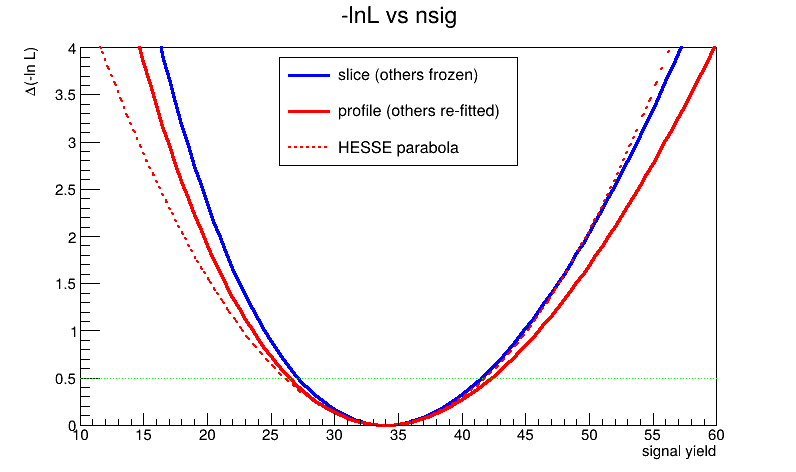

In [10]:
frame = nsig.frame(ROOT.RooFit.Range(10, 60), ROOT.RooFit.Title("-lnL vs nsig"))
# slice
nll.plotOn(frame, ROOT.RooFit.ShiftToZero(), ROOT.RooFit.Name("slice"))
# profile
prof = nll.createProfile(ROOT.RooArgSet(nsig))
prof.plotOn(frame, ROOT.RooFit.LineColor(ROOT.kRed), ROOT.RooFit.Name("profile"))
frame.SetMaximum(4)      # after plotOn, otherwise it is reset
frame.SetMinimum(0)
frame.GetYaxis().SetTitle("#Delta(-ln L)")

# the profile moves the other parameters: back to the best fit
params.assign(res.floatParsFinal())

# Draw a parabola with the same minimum and curvature as the NLL
parab = ROOT.TF1("parab", "0.5*((x-[0])/[1])**2", 10, 60)
parab.SetParameters(nsig.getVal(), err_hesse)
parab.SetLineStyle(2)

# Draw horizontal line at 0.5 (1 sigma for NLL, or 1.0 for -2lnL)
line = ROOT.TLine(10, 0.5, 60, 0.5)
line.SetLineColor(ROOT.kGreen)
line.SetLineStyle(ROOT.kDotted)

leg = ROOT.TLegend(0.35, 0.65, 0.65, 0.88)
leg.AddEntry(frame.findObject("slice"), "slice (others frozen)", "l")
leg.AddEntry(frame.findObject("profile"), "profile (others re-fitted)", "l")
leg.AddEntry(parab, "HESSE parabola", "l")

cs = ROOT.TCanvas("cs", "cs", 800, 500)
frame.Draw()
parab.Draw("same")
line.Draw("same")
leg.Draw()
cs.Draw()

In [11]:
# A4 in numbers: the three curves and their 68% intervals
params.assign(res.floatParsFinal())
nll_min = nll.getVal()
n_hat = nsig.getVal()

def slice_v(x):
    params.assign(res.floatParsFinal()); nsig.setVal(x)
    return nll.getVal() - nll_min
def prof_v(x):
    nsig.setVal(x)
    return prof.getVal()             # already 0 at the minimum
def parab_v(x):
    return 0.5 * ((x - n_hat) / err_hesse) ** 2

print("  nsig   slice  profile  parabola")
for x in [15, 20, 25, 30, n_hat, 40, 45, 50, 55, 60]:
    print("%6.1f  %6.3f  %6.3f  %6.3f" % (x, slice_v(x), prof_v(x), parab_v(x)))

xs = np.linspace(10, 60, 2001)
for name, fn in [("slice", slice_v), ("profile", prof_v), ("parabola", parab_v)]:
    ys = np.array([fn(x) for x in xs]); ok = xs[ys <= 0.5]
    print("%-9s 68%% interval [%.2f, %.2f]  ->  %+.2f / %+.2f" % (name, ok.min(), ok.max(), ok.min() - n_hat, ok.max() - n_hat))
params.assign(res.floatParsFinal())


  nsig   slice  profile  parabola
  15.0   4.766   3.842   2.882
  20.0   2.348   1.908   1.564
  25.0   0.890   0.727   0.646
  30.0   0.162   0.133   0.127
  34.0   0.000  -0.000   0.000
  40.0   0.323   0.268   0.289
  45.0   1.022   0.848   0.969
  50.0   2.046   1.697   2.049
  55.0   3.347   2.776   3.528
  60.0   4.888   4.049   5.407
slice     68% interval [27.15, 41.53]  ->  -6.84 / +7.54


profile   68% interval [26.48, 42.30]  ->  -7.51 / +8.31
parabola  68% interval [26.10, 41.88]  ->  -7.89 / +7.89


## A5: MINOS and Contours

`MINOS` finds asymmetric errors by scanning the profile likelihood. 
We can also visualize the joint uncertainty of two parameters using a **Contour**.

*Important RooFit Tip*: The `contour` method relies on the covariance matrix. Always call `hesse()` immediately before `contour()` to ensure the minimizer is in a clean, accurate state. Otherwise, you might see stray points or distorted ellipses.

Draw the 1σ and 2σ contours of (`nsig`, `nbkg`) with `minim.contour(...)`.

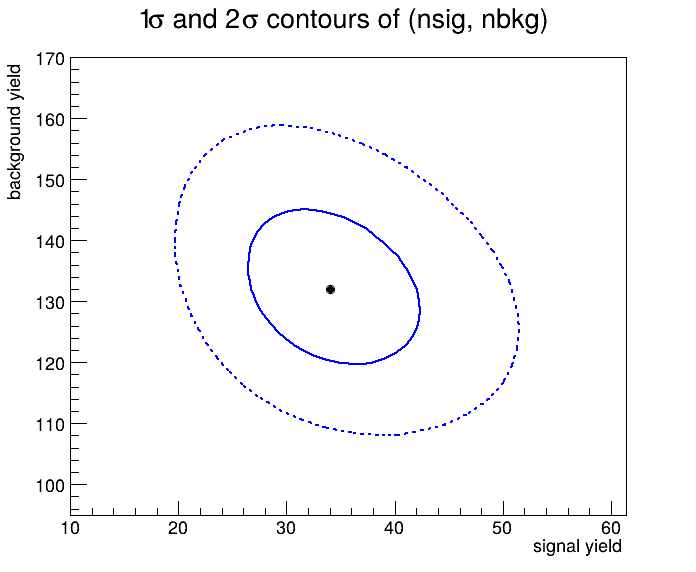

In [12]:
# back to the best fit (A4 moved the parameters)
params.assign(res.floatParsFinal())
# Ensure clean state to avoid stray dots in the contour!
minim.hesse()

cont = minim.contour(nsig, nbkg, 1, 2)   # returns a RooPlot
cont.SetTitle("1#sigma and 2#sigma contours of (nsig, nbkg)")
cont.GetXaxis().SetRangeUser(10, 60)
cont.GetYaxis().SetRangeUser(95, 170)
cc = ROOT.TCanvas("cc", "cc", 700, 600)
cont.Draw()
cc.Draw()

## Questions
Write your answer under each question, in 2–3 lines, and quote the numbers or plots of the steps indicated.

*Note: m range extended to [5080, 5560] MeV (as in Lab 1, Exercise C) so that all 166 events are read.*

1. **(A1, A2)** Compare the HESSE error and the two MINOS errors on `nsig`. Are they equal? If not, which MINOS error is longer (lower or upper), and what does it tell you about the shape of the likelihood?
- No. HESSE gives nsig = 33.99 ± 7.91, MINOS gives −7.54 / +8.33: the **upper** error is longer. The −lnL rises more slowly above the minimum than below it, so the likelihood is not a parabola but skewed to high nsig (Poisson-like: a yield is bounded at 0 and its variance grows with N). HESSE is roughly the average of the two: (7.54 + 8.33)/2 = 7.94.

2. **(A3)** Which pair of parameters has the largest correlation coefficient, in absolute value? Is it positive or negative? Explain with the model: if one parameter goes up, what must the other one do to keep the fit good?
- (nsig, sigma), ρ = **+0.36**, positive. A wider Gaussian covers more of the background under the peak, so it needs more signal events to fill it; a narrower one needs fewer. Next come (mean, sigma) −0.30 and (nsig, nbkg) −0.29: the latter is negative because the total yield is fixed by the data (≈ 166), so an event given to the signal is taken from the background.

3. **(A4)** In which range of `nsig` do the three curves (NLL scan, profile, HESSE parabola) differ the most, and where do they agree? What does this say about the likelihood, and which error would you quote?
- They agree near the minimum (30 < nsig < 40, ΔNLL differences < 0.06) and differ most in the tails: at nsig = 15 slice 4.77, profile 3.84, parabola 2.88; at nsig = 60: 4.89, 4.05, 5.41. The profile always lies below the slice (re-fitting the other parameters can only lower −lnL), so its interval is wider: slice −6.84/+7.54, profile −7.51/+8.31 (= MINOS), parabola ±7.89. The likelihood is asymmetric and not parabolic, and the slice ignores the nuisance parameters: I would quote the profile/MINOS result, **nsig = 34.0 −7.5 +8.3**.